# 08 — Final Model Evaluation
## Goal
Perform the final diagnostics on the best regression model selected from the previous notebook.

This notebook focuses on **regression diagnostics**, not classification.

### Important
A confusion matrix is **not a Linear Regression metric**. It requires discrete classes and predictions such as positive/negative or on-time/delayed.

For this project the primary task is continuous prediction of minutes, so we use MAE, RMSE, R² and residual diagnostics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("../outputs/cleaned/zomato_model_dataset.csv")
target = "Time_taken (min)"

X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

num = X.select_dtypes(include=["number"]).columns.tolist()
cat = X.select_dtypes(exclude=["number"]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat)
])

# Put the chosen hyperparameter from notebook 07 here after inspecting its result.
# The default below is a starting value; replace it with the GridSearchCV winner.
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", ElasticNet(alpha=0.001, l1_ratio=0.9, max_iter=10000))
])

final_model.fit(X_train, y_train)
pred = final_model.predict(X_test)

final_metrics = pd.DataFrame([{
    "Model": "Final ElasticNet",
    "MAE": mean_absolute_error(y_test, pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
    "R2": r2_score(y_test, pred)
}])

final_metrics.round(3)

,Model,MAE,RMSE,R2
0,Final ElasticNet,4.816,6.057,0.584


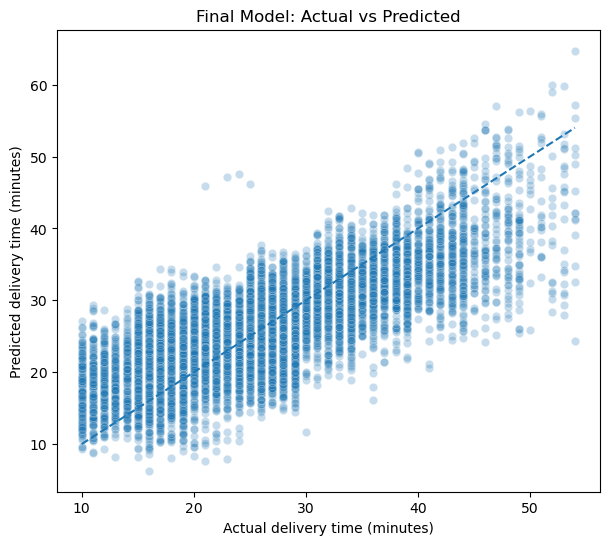

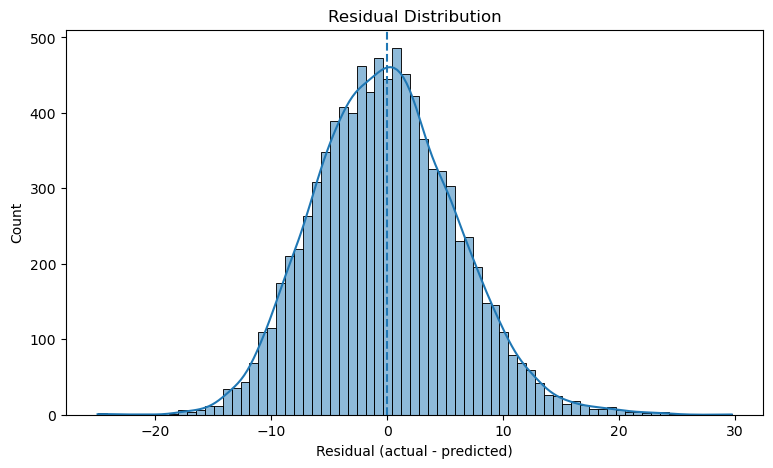

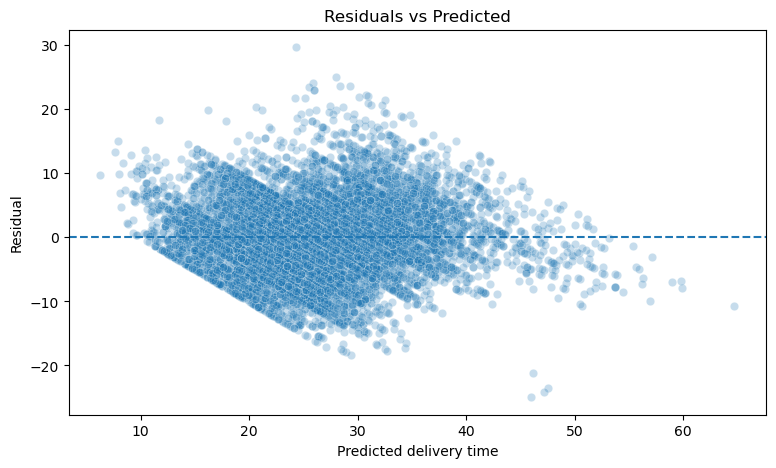

In [2]:
# Actual vs predicted
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=pred, alpha=0.25)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle="--")
plt.xlabel("Actual delivery time (minutes)")
plt.ylabel("Predicted delivery time (minutes)")
plt.title("Final Model: Actual vs Predicted")
plt.show()

# Residual distribution
residuals = y_test - pred
plt.figure(figsize=(9, 5))
sns.histplot(residuals, kde=True)
plt.axvline(0, linestyle="--")
plt.title("Residual Distribution")
plt.xlabel("Residual (actual - predicted)")
plt.show()

# Residuals vs predictions
plt.figure(figsize=(9, 5))
sns.scatterplot(x=pred, y=residuals, alpha=0.25)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted delivery time")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted")
plt.show()

In [5]:
# Error summary by actual delivery-time bucket
diagnostic = pd.DataFrame({
    "actual": y_test.values,
    "predicted": pred
})
diagnostic["absolute_error"] = (diagnostic["actual"] - diagnostic["predicted"]).abs()
diagnostic["actual_bucket"] = pd.cut(
      diagnostic["actual"],
    bins=[0, 20, 30, 40, np.inf],
    labels=["<=20", "21-30", "31-40", ">40"],
    right=True,
    include_lowest=True
)

diagnostic.groupby("actual_bucket", observed=False)["absolute_error"].agg(
    ["count", "mean", "median"]
).round(3)

,count,mean,median
actual_bucket,,,
<=20,2850,5.593,5.163
21-30,3549,3.663,3.072
31-40,1914,4.393,3.783
>40,804,8.159,7.531


## Final interpretation checklist

Before calling the model "good", answer:

1. Did it beat the mean baseline?
2. Is the train/test gap acceptable?
3. Are residuals roughly centered around zero?
4. Does the residual plot show a pattern?
5. Are errors much larger for long deliveries?
6. Are there groups where the model systematically underpredicts?
7. Does the model use only information available at order placement?
8. Can we explain the prediction to a non-technical stakeholder?

The final model should be selected from evidence, not because a particular algorithm is fashionable.